# 07. Reconnaissance du risque de sous-estimation

> **English Overview (Step 7 — Ex-Ante Recognition of Underestimation Risk):** Tests two non-refitted ex-ante alert rules calibrated at the 90th percentile of 1990–2015 (`HV20 > 26.32%` and `HV5/HV20 > 1.3561`) to detect the 13 common underestimation episodes on 2016–2019. Both rules fail as early-warning indicators (detecting `0/13` and `1/13` episode starts, with daily precision no better than the 4.40% base rate).

**Question exploratoire :** les niveaux historiques de volatilité ou leur accélération récente permettent-ils de reconnaître les dates auxquelles les cinq modèles risquent de fortement sous-estimer `RV5` ?

Deux règles seulement sont examinées, sans apprentissage ni optimisation : `HV20` et `HV5/HV20`, chacune comparée à son 90e centile sur 1990–2015. La période 2016–2019 a déjà été explorée : les résultats ne constituent pas une validation indépendante.

## 1. Données et conventions temporelles

In [1]:
from hashlib import sha256
from io import BytesIO, StringIO
from pathlib import Path
from zipfile import ZipFile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

EXPECTED_SHA256 = '2f29e22546069914890a712680a6f81f3680ebc3543b52864484d209ca13a7db'
SNAPSHOT_FILENAME = (
    'F-F_Research_Data_Factors_daily_202608_'
    f'sha256-{EXPECTED_SHA256}.zip'
)
HORIZON = 5
ANNUALIZATION_DAYS = 252
COMMON_THRESHOLD = 10.931
plt.style.use('seaborn-v0_8-whitegrid')

In [2]:
snapshot_candidates = [
    Path('data/raw/fama_french') / SNAPSHOT_FILENAME,
    Path('../data/raw/fama_french') / SNAPSHOT_FILENAME,
]
snapshot = next((path for path in snapshot_candidates if path.is_file()), None)
assert snapshot is not None, 'La copie locale immuable validée est introuvable.'
archive_bytes = snapshot.read_bytes()
assert sha256(archive_bytes).hexdigest() == EXPECTED_SHA256

with ZipFile(BytesIO(archive_bytes)) as archive:
    members = archive.namelist()
    assert len(members) == 1
    text = archive.read(members[0]).decode('utf-8-sig')

lines = text.splitlines()
header_index = next(i for i, line in enumerate(lines) if line.strip().startswith(',Mkt-RF'))
data_lines = [lines[header_index]]
for line in lines[header_index + 1:]:
    first_field = line.split(',', 1)[0].strip()
    if len(first_field) == 8 and first_field.isdigit():
        data_lines.append(line)
    else:
        break

factors = pd.read_csv(StringIO('\n'.join(data_lines)))
factors = factors.rename(columns={factors.columns[0]: 'date'})
factors['date'] = pd.to_datetime(factors['date'].astype(str), format='%Y%m%d', errors='raise')
factors = factors.set_index('date')
assert factors.index.is_monotonic_increasing and not factors.index.has_duplicates
market_return = (factors['Mkt-RF'] + factors['RF']) / 100.0
print(f'Snapshot local : {snapshot.as_posix()}')
print(f'SHA-256 : {EXPECTED_SHA256}')
print(f'Période brute : {factors.index.min().date()} → {factors.index.max().date()}')

Snapshot local : ../data/raw/fama_french/F-F_Research_Data_Factors_daily_202608_sha256-2f29e22546069914890a712680a6f81f3680ebc3543b52864484d209ca13a7db.zip
SHA-256 : 2f29e22546069914890a712680a6f81f3680ebc3543b52864484d209ca13a7db
Période brute : 1926-07-01 → 2026-08-31


In [3]:
future_returns = pd.concat(
    {f'r_t_plus_{k}': market_return.shift(-k) for k in range(1, HORIZON + 1)}, axis=1
)
rv_5 = np.sqrt(
    (ANNUALIZATION_DAYS / HORIZON)
    * future_returns.pow(2).sum(axis=1, min_count=HORIZON)
)
data = pd.DataFrame(index=factors.index)
data['market_return'] = market_return
for window in [5, 20]:
    data[f'hv_{window}'] = np.sqrt(
        (ANNUALIZATION_DAYS / window)
        * market_return.pow(2).rolling(window, min_periods=window).sum()
    )
data['ratio_hv5_hv20'] = data.hv_5 / data.hv_20
data['rv_5'] = rv_5
data['target_start'] = factors.index.to_series(index=factors.index).shift(-1)
data['target_end'] = factors.index.to_series(index=factors.index).shift(-HORIZON)

history = data.loc['1990-01-01':'2015-12-31', ['hv_20', 'ratio_hv5_hv20']].copy()
evaluation = data.loc[
    (data.index >= '2016-01-01') & (data.target_end <= '2019-12-31'),
    ['hv_5', 'hv_20', 'ratio_hv5_hv20', 'rv_5', 'target_start', 'target_end'],
].dropna().copy()
assert len(evaluation) == 1001
assert evaluation.target_start.gt(evaluation.index.to_series()).all()
assert evaluation.target_end.gt(evaluation.index.to_series()).all()
assert evaluation.target_end.max() <= pd.Timestamp('2019-12-31')
print(f'Historique des seuils : {history.dropna().index.min().date()} → {history.dropna().index.max().date()}')
print(f'Évaluation : {evaluation.index.min().date()} → {evaluation.index.max().date()}, {len(evaluation):,} dates')

Historique des seuils : 1990-01-02 → 2015-12-31
Évaluation : 2016-01-04 → 2019-12-23, 1,001 dates


## 2. Événements établis dans le notebook 06

Les modèles ne sont pas réentraînés. Les bornes des 13 épisodes du benchmark initial sont reprises du notebook 06. Les assertions vérifient qu'elles reconstruisent exactement 44 dates communes et 13 débuts.

In [4]:
EPISODE_BOUNDS = [
    ('2016-01-06', '2016-01-06'),
    ('2016-06-17', '2016-06-23'),
    ('2016-09-06', '2016-09-08'),
    ('2018-01-29', '2018-02-02'),
    ('2018-03-16', '2018-03-23'),
    ('2018-10-03', '2018-10-09'),
    ('2018-10-19', '2018-10-23'),
    ('2018-11-27', '2018-11-27'),
    ('2018-11-29', '2018-12-03'),
    ('2018-12-18', '2018-12-24'),
    ('2019-05-06', '2019-05-06'),
    ('2019-07-29', '2019-08-02'),
    ('2019-08-07', '2019-08-07'),
]

common_failure = pd.Series(False, index=evaluation.index, name='C_t')
episode_id = pd.Series(pd.NA, index=evaluation.index, dtype='Int64', name='episode')
for number, (start, end) in enumerate(EPISODE_BOUNDS, start=1):
    in_episode = evaluation.index.to_series().between(pd.Timestamp(start), pd.Timestamp(end))
    common_failure.loc[in_episode] = True
    episode_id.loc[in_episode] = number
episode_start = common_failure & ~common_failure.shift(fill_value=False)

assert int(common_failure.sum()) == 44
assert int(episode_start.sum()) == 13
assert episode_id.nunique() == 13
assert evaluation.index[episode_start].tolist() == [pd.Timestamp(x[0]) for x in EPISODE_BOUNDS]
print(f'Seuil de sous-estimation repris : {COMMON_THRESHOLD:.3f} points')
print(f'Concordance notebook 06 : {common_failure.sum()} dates, {episode_start.sum()} débuts, {episode_id.nunique()} épisodes')

Seuil de sous-estimation repris : 10.931 points
Concordance notebook 06 : 44 dates, 13 débuts, 13 épisodes


## 3. Deux alertes fixées sans optimisation

In [5]:
signal_columns = {'A — niveau HV20': 'hv_20', 'B — accélération HV5/HV20': 'ratio_hv5_hv20'}
invalid = pd.DataFrame({
    'manquantes_historique': history[list(signal_columns.values())].isna().sum(),
    'non_finies_historique': (~np.isfinite(history[list(signal_columns.values())])).sum(),
    'manquantes_evaluation': evaluation[list(signal_columns.values())].isna().sum(),
    'non_finies_evaluation': (~np.isfinite(evaluation[list(signal_columns.values())])).sum(),
})
assert evaluation.hv_20.gt(0).all()
assert evaluation[list(signal_columns.values())].notna().all().all()
assert np.isfinite(evaluation[list(signal_columns.values())]).all().all()

thresholds = history[list(signal_columns.values())].quantile(.90)
alerts = pd.DataFrame({
    rule: evaluation[column].gt(thresholds[column])
    for rule, column in signal_columns.items()
}, index=evaluation.index)
assert alerts.notna().all().all()

threshold_table = pd.DataFrame({
    'signal': list(signal_columns.values()),
    'observations_historiques_valides': [history[c].notna().sum() for c in signal_columns.values()],
    'seuil_q90': [thresholds[c] for c in signal_columns.values()],
    'dates_alerte_2016_2019': [alerts[r].sum() for r in signal_columns],
}, index=signal_columns)
print('Valeurs invalides :')
print(invalid.to_string())
print('\nSeuils figés avant évaluation :')
print(threshold_table.round(4).to_string())

Valeurs invalides :
                manquantes_historique  non_finies_historique  manquantes_evaluation  non_finies_evaluation
hv_20                               0                      0                      0                      0
ratio_hv5_hv20                      0                      0                      0                      0

Seuils figés avant évaluation :
                                       signal  observations_historiques_valides  seuil_q90  dates_alerte_2016_2019
A — niveau HV20                       hv_20                              6553     0.2632                      19
B — accélération HV5/HV20  ratio_hv5_hv20                              6553     1.3561                     119


In [6]:
availability_audit = pd.DataFrame({
    'origine_t': evaluation.index[:3],
    'début_HV5': [factors.index[factors.index.get_loc(t)-4] for t in evaluation.index[:3]],
    'début_HV20': [factors.index[factors.index.get_loc(t)-19] for t in evaluation.index[:3]],
    'fin_signaux': evaluation.index[:3],
    'début_cible': evaluation.target_start.iloc[:3].to_numpy(),
    'fin_cible': evaluation.target_end.iloc[:3].to_numpy(),
})
assert (availability_audit['fin_signaux'] <= availability_audit['origine_t']).all()
assert (availability_audit['début_cible'] > availability_audit['origine_t']).all()
print(availability_audit.to_string(index=False))
print('Les deux signaux se terminent à t ; RV5 commence à t+1 et se termine à t+5.')

 origine_t début_HV5 début_HV20 fin_signaux début_cible  fin_cible
2016-01-04 2015-12-28  2015-12-04  2016-01-04   2016-01-05 2016-01-11
2016-01-05 2015-12-29  2015-12-07  2016-01-05   2016-01-06 2016-01-12
2016-01-06 2015-12-30  2015-12-08  2016-01-06   2016-01-07 2016-01-13
Les deux signaux se terminent à t ; RV5 commence à t+1 et se termine à t+5.


## 4. Débuts reconnus et précision quotidienne

Le rappel des débuts utilise les 13 premières dates. La précision quotidienne utilise les 44 dates où `C(t)=1`. Une alerte pendant un épisode est correcte au sens quotidien, mais elle est tardive et ne compte pas comme début reconnu.

In [7]:
def consecutive_ids(mask):
    mask = pd.Series(mask, index=evaluation.index).astype(bool)
    starts = mask & ~mask.shift(fill_value=False)
    return starts.cumsum().where(mask)

def rule_metrics(alert):
    total_alerts = int(alert.sum())
    daily_hits = int((alert & common_failure).sum())
    false_alerts = int((alert & ~common_failure).sum())
    starts_hit = int((alert & episode_start).sum())
    late_alerts = int((alert & common_failure & ~episode_start).sum())
    ids = consecutive_ids(alert)
    durations = ids.dropna().value_counts().sort_index()
    return pd.Series({
        'dates_alerte': total_alerts,
        'taux_alerte_pct': 100 * total_alerts / len(evaluation),
        'débuts_reconnus_sur_13': starts_hit,
        'rappel_débuts_pct': 100 * starts_hit / 13,
        'débuts_manqués': 13 - starts_hit,
        'alertes_sur_Ct_1': daily_hits,
        'précision_quotidienne_pct': 100 * daily_hits / total_alerts if total_alerts else np.nan,
        'écart_précision_base_pp': (100 * daily_hits / total_alerts - 100 * common_failure.mean()) if total_alerts else np.nan,
        'épisodes_Ct_touchés': int(episode_id.loc[alert & common_failure].nunique()),
        'fausses_alertes': false_alerts,
        'fausses_alertes_pour_100_séances': 100 * false_alerts / len(evaluation),
        'alertes_tardives': late_alerts,
        'épisodes_alerte': int(ids.nunique()),
        'durée_médiane_alerte': float(durations.median()) if len(durations) else np.nan,
        'durée_max_alerte': int(durations.max()) if len(durations) else 0,
    })

results = pd.DataFrame({rule: rule_metrics(alerts[rule]) for rule in alerts}).T
baselines = pd.DataFrame({
    'valeur_pct': [
        100 * common_failure.mean(),
        100 * episode_start.mean(),
        0.0,
    ]
}, index=[
    'Fréquence quotidienne C(t)=1',
    'Fréquence quotidienne des débuts',
    'Rappel des débuts sans aucune alerte',
])
print(results.round(3).to_string())
print('\nRéférences :')
print(baselines.round(3).to_string())

                               dates_alerte  taux_alerte_pct  débuts_reconnus_sur_13  rappel_débuts_pct  débuts_manqués  alertes_sur_Ct_1  précision_quotidienne_pct  écart_précision_base_pp  épisodes_Ct_touchés  fausses_alertes  fausses_alertes_pour_100_séances  alertes_tardives  épisodes_alerte  durée_médiane_alerte  durée_max_alerte
A — niveau HV20                      19.0            1.898                      0.0               0.000              13.0               0.0                       0.000                     -4.396                    0.0             19.0                              1.898               0.0               1.0                    19.0               19.0
B — accélération HV5/HV20         119.0           11.888                      1.0               7.692              12.0               5.0                       4.202                     -0.194                    5.0            114.0                             11.389               4.0              41.0           

In [8]:
episode_rows = []
for number, (start_text, end_text) in enumerate(EPISODE_BOUNDS, start=1):
    start, end = pd.Timestamp(start_text), pd.Timestamp(end_text)
    start_position = evaluation.index.get_loc(start)
    end_position = evaluation.index.get_loc(end)
    before = evaluation.index[max(0, start_position-HORIZON):start_position]
    during = evaluation.index[start_position:end_position+1]
    after = evaluation.index[end_position+1:min(len(evaluation), end_position+1+HORIZON)]
    row = {'épisode': number, 'début': start, 'fin': end, 'durée': len(during)}
    for rule in alerts:
        short = 'A' if rule.startswith('A') else 'B'
        row[f'{short}_avant_5j'] = ', '.join(d.strftime('%Y-%m-%d') for d in before[alerts.loc[before, rule]]) or '—'
        row[f'{short}_au_début'] = bool(alerts.loc[start, rule])
        row[f'{short}_pendant_tardif'] = ', '.join(
            d.strftime('%Y-%m-%d') for d in during[1:][alerts.loc[during[1:], rule]]
        ) or '—'
        row[f'{short}_après_5j'] = ', '.join(d.strftime('%Y-%m-%d') for d in after[alerts.loc[after, rule]]) or '—'
    episode_rows.append(row)
episode_chronology = pd.DataFrame(episode_rows).set_index('épisode')
print(episode_chronology.to_string())

             début        fin  durée A_avant_5j  A_au_début A_pendant_tardif                                                 A_après_5j                          B_avant_5j  B_au_début B_pendant_tardif                                                 B_après_5j
épisode                                                                                                                                                                                                                                                                 
1        2016-01-06 2016-01-06       1        —        False              —                                                         —                                 —        False              —                                                         —
2        2016-06-17 2016-06-23       5        —        False              —                                                         —                                 —        False       2016-06-23  2016-06-24, 2016-06-27

Les colonnes « avant » et « après » couvrent cinq séances uniquement pour situer les alertes autour des épisodes. Elles ne changent pas la définition d'un succès : seule une alerte à la date exacte du début reconnaît ce début. Une même alerte peut apparaître dans deux fenêtres descriptives lorsque des épisodes sont proches.

## 5. Sensibilité aux cinq décalages non chevauchants

In [9]:
offset_rows = []
for offset in range(HORIZON):
    index = evaluation.index[offset::HORIZON]
    spaced = evaluation.loc[index]
    assert (spaced.target_start.iloc[1:].to_numpy() > spaced.target_end.iloc[:-1].to_numpy()).all()
    for rule in alerts:
        alert = alerts.loc[index, rule]
        common = common_failure.loc[index]
        starts = episode_start.loc[index]
        n_alert = int(alert.sum())
        offset_rows.append({
            'décalage': offset,
            'règle': rule,
            'observations': len(index),
            'dates_Ct_1': int(common.sum()),
            'débuts_présents': int(starts.sum()),
            'alertes': n_alert,
            'alertes_sur_Ct_1': int((alert & common).sum()),
            'précision_quotidienne_pct': 100*(alert & common).sum()/n_alert if n_alert else np.nan,
            'débuts_reconnus': int((alert & starts).sum()),
            'fausses_alertes_pour_100': 100*(alert & ~common).sum()/len(index),
        })
offset_sensitivity = pd.DataFrame(offset_rows).set_index(['décalage', 'règle'])
print(offset_sensitivity.round(3).to_string())

                                         observations  dates_Ct_1  débuts_présents  alertes  alertes_sur_Ct_1  précision_quotidienne_pct  débuts_reconnus  fausses_alertes_pour_100
décalage règle                                                                                                                                                                       
0         A — niveau HV20                       201           9                  4        4                 0                       0.000                 0                     1.990
          B — accélération HV5/HV20           201           9                  4       28                 2                       7.143                 0                    12.935
1         A — niveau HV20                       200           9                  2        4                 0                       0.000                 0                     2.000
          B — accélération HV5/HV20           200           9                  2       24     

Ces cinq sous-échantillons suppriment le chevauchement des cibles au sein de chaque décalage. Leurs faibles effectifs, notamment pour les débuts d'épisodes, interdisent de les traiter comme cinq validations indépendantes.

## 6. Visualisation utile

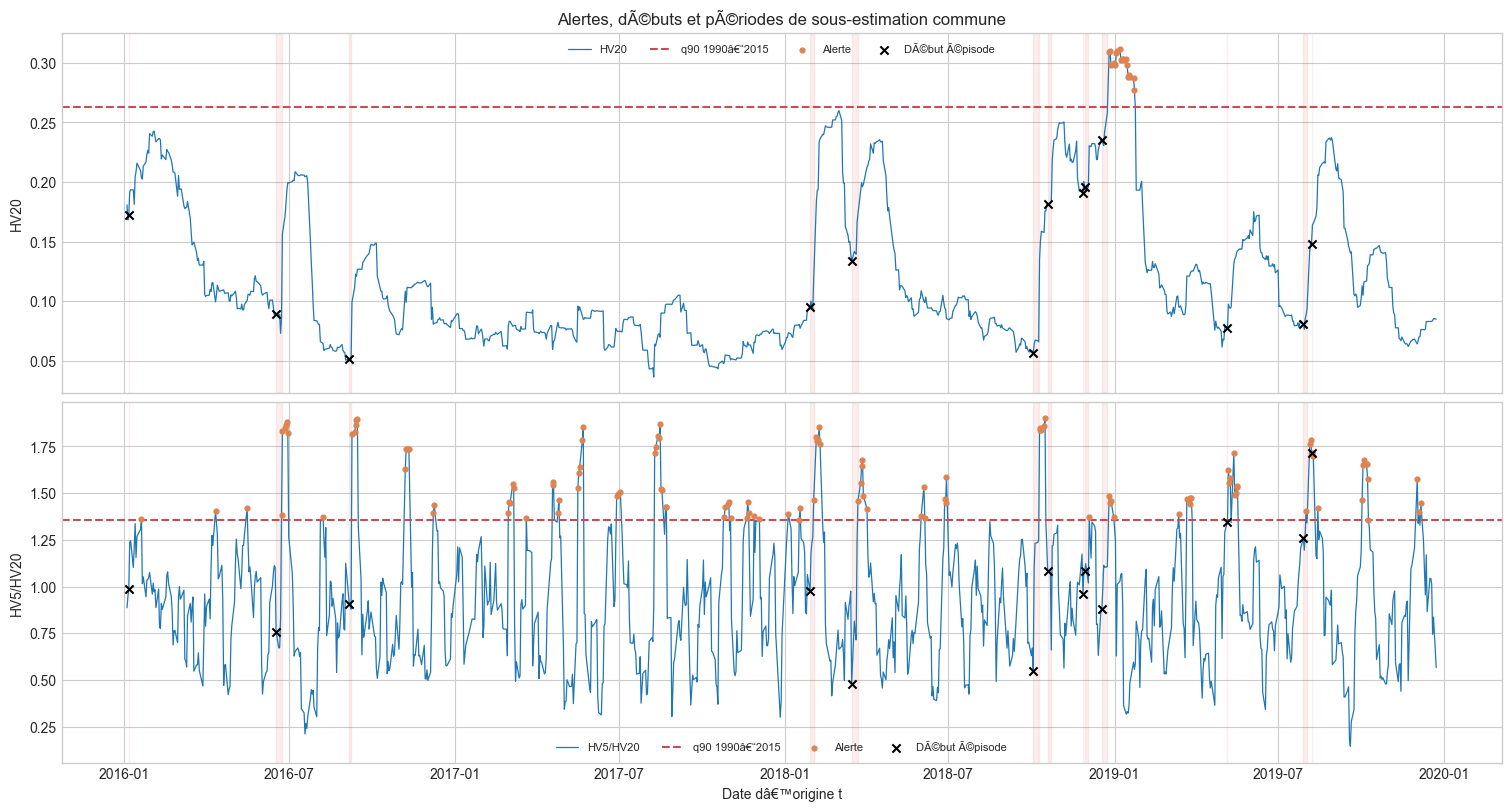

In [10]:
fig, axes = plt.subplots(2, 1, figsize=(15, 8), sharex=True, constrained_layout=True)
plot_specs = [
    ('A — niveau HV20', 'hv_20', thresholds.hv_20, 'HV20'),
    ('B — accélération HV5/HV20', 'ratio_hv5_hv20', thresholds.ratio_hv5_hv20, 'HV5/HV20'),
]
for ax, (rule, column, threshold, label) in zip(axes, plot_specs):
    ax.plot(evaluation.index, evaluation[column], linewidth=.9, label=label)
    ax.axhline(threshold, color='#c44e52', linestyle='--', label='q90 1990–2015')
    ax.scatter(evaluation.index[alerts[rule]], evaluation.loc[alerts[rule], column],
               s=12, color='#dd8452', label='Alerte', zorder=3)
    ax.scatter(evaluation.index[episode_start], evaluation.loc[episode_start, column],
               s=35, marker='x', color='black', label='Début épisode', zorder=4)
    for start, end in EPISODE_BOUNDS:
        ax.axvspan(pd.Timestamp(start), pd.Timestamp(end), color='#d62728', alpha=.08)
    ax.set_ylabel(label)
    ax.legend(ncol=4, fontsize=8)
axes[0].set_title('Alertes, débuts et périodes de sous-estimation commune')
axes[1].set_xlabel('Date d’origine t')
plt.show()

## 7. Synthèse calculée

In [11]:
print('SYNTHÈSE DES EFFECTIFS')
print(f'Base quotidienne : {common_failure.sum()}/{len(evaluation)} = {100*common_failure.mean():.2f} % de dates C(t)=1.')
print(f'Base des débuts : {episode_start.sum()}/{len(evaluation)} = {100*episode_start.mean():.2f} %.')
for rule in alerts:
    r = results.loc[rule]
    print(
        f"{rule}: {int(r['dates_alerte'])} alertes; "
        f"{int(r['débuts_reconnus_sur_13'])}/13 débuts reconnus; "
        f"{int(r['alertes_sur_Ct_1'])} alertes sur C(t)=1, dont {int(r['alertes_tardives'])} tardives; "
        f"précision quotidienne {r['précision_quotidienne_pct']:.2f} %; "
        f"{r['fausses_alertes_pour_100_séances']:.2f} fausses alertes pour 100 séances."
    )

SYNTHÈSE DES EFFECTIFS
Base quotidienne : 44/1001 = 4.40 % de dates C(t)=1.
Base des débuts : 13/1001 = 1.30 %.
A — niveau HV20: 19 alertes; 0/13 débuts reconnus; 0 alertes sur C(t)=1, dont 0 tardives; précision quotidienne 0.00 %; 1.90 fausses alertes pour 100 séances.
B — accélération HV5/HV20: 119 alertes; 1/13 débuts reconnus; 5 alertes sur C(t)=1, dont 4 tardives; précision quotidienne 4.20 %; 11.39 fausses alertes pour 100 séances.


## 8. Interprétation scientifique

### 8.1. Faits observés

- L'alerte de niveau `HV20` ne se déclenche que 19 fois, en un seul bloc continu. Elle ne reconnaît aucun des 13 débuts et ne coïncide avec aucune des 44 dates de sous-estimation commune. Ses 19 déclenchements sont donc des fausses alertes quotidiennes selon la définition retenue.
- L'alerte d'accélération `HV5/HV20` se déclenche 119 fois, soit 11,9 % des séances. Elle reconnaît un seul début sur 13 (7,7 %) et manque les douze autres.
- Parmi ces 119 alertes, cinq seulement correspondent à `C(t)=1`, soit une précision quotidienne de 4,2 %. Cette proportion est légèrement inférieure à la fréquence de base de `C(t)=1` sur l'ensemble des dates, 4,4 %. Les 114 autres alertes représentent 11,39 fausses alertes pour 100 séances.
- Quatre des cinq alertes quotidiennes correctes de la règle d'accélération sont tardives. Les cinq dates correctes concernent cinq épisodes distincts, mais quatre alertes ne deviennent actives qu'après leur début.
- Les décalages non chevauchants ne montrent aucune régularité uniforme : la règle d'accélération ne rencontre `C(t)=1` que dans deux décalages sur cinq, et l'unique début reconnu appartient à un seul décalage. Ce diagnostic ne constitue pas cinq tests indépendants.

### 8.2. Ce que ces résultats suggèrent

Un niveau de `HV20` exceptionnellement élevé ne constitue pas ici un signal précoce : le seuil n'est franchi qu'après que certains mouvements ont déjà accru la volatilité historique. Le ratio `HV5/HV20` réagit plus souvent et capte cinq dates de défaillance, mais essentiellement après le début des épisodes. Son taux élevé de fausses alertes et sa précision voisine de la fréquence de base indiquent qu'il décrit surtout des accélérations courantes, sans discriminer utilement les sous-estimations communes sur cette période.

Les deux règles échouent donc à fournir une reconnaissance satisfaisante des débuts d'épisodes. Ce résultat est cohérent avec le notebook 06 : aux débuts, l'information récente ne présentait pas de configuration simple et uniforme. Il ne démontre toutefois pas que les épisodes sont intrinsèquement imprévisibles, ni qu'aucune information disponible à `t` ne pourrait être utile.

### 8.3. Limites

La période 2016–2019 a déjà orienté la formulation de la question ; cette analyse reste exploratoire. Les 44 dates se chevauchent et ne sont pas 44 événements indépendants. Les 13 débuts sont trop peu nombreux pour rechercher de nombreux seuils ou signaux sans surapprentissage. Le 90e centile fixe une règle transparente, mais aucune fonction de coût financier ne permet d'affirmer qu'une fréquence d'alerte particulière est optimale. Enfin, une forte volatilité n'est pas automatiquement une perte financière.

### 8.4. Question qui en découle

La question naturelle n'est pas de modifier les seuils jusqu'à obtenir un meilleur résultat. Elle est de déterminer si l'échec provient de l'absence de signal dans les seuls rendements historiques avant le mouvement, ou d'une représentation trop pauvre de l'information déjà disponible à `t`. Cette question exige une décision scientifique distincte et, pour une conclusion confirmatoire, une période réellement non consultée. Aucune extension n'est engagée ici.